#1: Load Data
- Download train.json & test.json
- Read them using pandas

In [14]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the data
train = pd.read_json("train.json")   # has: id, cuisine, ingredients
test = pd.read_json("test.json")     # has: id, ingredients

print("Train shape:", train.shape)
print("Test shape:", test.shape)


Train shape: (29774, 3)
Test shape: (10000, 2)


#Logistic Regression

In [15]:
from sklearn.preprocessing import OneHotEncoder
from scipy.special import softmax

onehot_encoder = OneHotEncoder(sparse_output=False)

def loss(X, Y_onehot, W, mu):
    """
    X: (N, D) feature matrix
    Y_onehot: (N, C) one-hot labels
    W: (D, C) weight matrix
    mu: regularization strength
    """
    logits = X @ W                     # (N, C)
    P = softmax(logits, axis=1)        # (N, C)
    N = X.shape[0]

    ce = -np.sum(Y_onehot * np.log(P + 1e-15)) / N   # cross-entropy
    reg = mu * np.sum(W * W)                         # L2 regularization
    return ce + reg

def gradient(X, Y_onehot, W, mu):
    """
    Gradient of the loss wrt W
    """
    logits = X @ W
    P = softmax(logits, axis=1)
    N = X.shape[0]

    grad_W = X.T @ (P - Y_onehot) / N + 2 * mu * W   # (D, C)
    return grad_W


def gradient_descent(X, Y, max_iter=5000, eta=0.4, mu=0.001):
    """
    Batch gradient descent for multiclass logistic regression
    Y: 1D array of labels (strings or ints)
    """
    Y = np.asarray(Y)
    if Y.ndim > 1:
        Y = Y.ravel()

    Y_onehot = onehot_encoder.fit_transform(Y.reshape(-1,1))
    W = np.zeros((X.shape[1], Y_onehot.shape[1]))

    step_lst, loss_lst = [], []

    for step in range(1, max_iter + 1):
        grad_W = gradient(X, Y_onehot, W, mu)
        W -= eta * grad_W

        current_loss = loss(X, Y_onehot, W, mu)
        step_lst.append(step)
        loss_lst.append(current_loss)

        # if step % 10 == 0 or step == 1:
        #     print(f"Step {step:4d}  Loss: {current_loss:.4f}")

    df = pd.DataFrame({"step": step_lst, "loss": loss_lst})
    return df, W


class Multiclass:
    def fit(self, X, Y):
        self.loss_steps, self.W = gradient_descent(X, Y)

    def loss_plot(self):
        return self.loss_steps.plot(
            x='step',
            y='loss',
            xlabel='step',
            ylabel='loss'
        )

    def predict(self, H):
        logits = H @ self.W
        P = softmax(logits, axis=1)
        return np.argmax(P, axis=1)


#2: Data Preprocessing

What to clean:

✔ Lowercase all ingredients

✔ Remove punctuation

✔ Remove duplicates if needed

Most importantly:
Convert ingredients → features using Vectorization Techniques

Options:
- Count Vectorizer (basic)
- TF-IDF Vectorizer (better for classification)

In [16]:
# 2. Preprocess ingredients
#    - keep each ingredient string as ONE token
def clean_ingredients(ing_list):
    # lower-case and strip spaces for consistency
    return [i.lower().strip() for i in ing_list]

train["ingredients_clean"] = train["ingredients"].apply(clean_ingredients)
test["ingredients_clean"] = test["ingredients"].apply(clean_ingredients)

# 3. Create TF-IDF features
#    Each ingredient phrase is treated as one feature
vectorizer = TfidfVectorizer(
    tokenizer=lambda x: x,        # we give it a list of tokens directly
    preprocessor=lambda x: x,     # do not turn list to string
    token_pattern=None,           # because we override tokenizer
    min_df= 1                    # ignore ingredients that appear in only 1 recipe
)

X = vectorizer.fit_transform(train["ingredients_clean"])
X_test_final = vectorizer.transform(test["ingredients_clean"])
y = train["cuisine"]

print("Feature matrix shape (X):", X.shape)
print("Test feature matrix shape:", X_test_final.shape)
print("Example features:\n", list(vectorizer.vocabulary_.keys())[:50])

Feature matrix shape (X): (29774, 6203)
Test feature matrix shape: (10000, 6203)
Example features:
 ['egg whites', 'pecans', 'agave nectar', 'ground cinnamon', 'sea salt', 'large egg whites', 'whole milk', 'bread crumb fresh', 'large eggs', 'lemon wedge', 'tarama', 'french bread', 'russet potatoes', 'safflower oil', 'olive oil', 'green onions', 'sugar', 'vegetable oil', 'yeast', 'eggs', 'evaporated milk', 'confectioners sugar', 'water', 'salt', 'shortening', 'flour', 'boiling water', 'honey', 'rice vinegar', 'brown sugar', 'ginger', 'garlic cloves', 'chicken wings', 'sesame oil', 'gochujang base', 'soy sauce', 'mushroom caps', 'asiago', 'large shrimp', 'fat free less sodium chicken broth', 'chopped fresh chives', 'fettucine', 'finely chopped onion', 'dry white wine', 'flat leaf parsley', 'peppercorns', 'pepper', 'garlic', 'shrimp', 'rum']


#3. EDA for Cuisine Classification Dataset

Step 1: Load & Inspect the Data

We will analyze:

1️⃣ Basic data checks

2️⃣ Cuisine distribution

3️⃣ Number of ingredients per recipe

4️⃣ Most common ingredients

5️⃣ Ingredient frequency by cuisine

6️⃣ Word clouds (optional but cool!)


In [17]:
train.head()
train.info()
train.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29774 entries, 0 to 29773
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   id                 29774 non-null  int64 
 1   cuisine            29774 non-null  object
 2   ingredients        29774 non-null  object
 3   ingredients_clean  29774 non-null  object
dtypes: int64(1), object(3)
memory usage: 930.6+ KB


,id,cuisine,ingredients,ingredients_clean
count,29774.000000,29774,29774,29774
unique,NaN,20,29715,29715
top,NaN,italian,"[vegetable oil, pappadams]","[vegetable oil, pappadams]"
freq,NaN,5910,2,2
mean,24818.685531,NaN,NaN,NaN
std,14326.299381,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN
25%,12434.000000,NaN,NaN,NaN
50%,24833.500000,NaN,NaN,NaN
75%,37269.500000,NaN,NaN,NaN


Step 2: Check Cuisine Distribution (Class Imbalance)

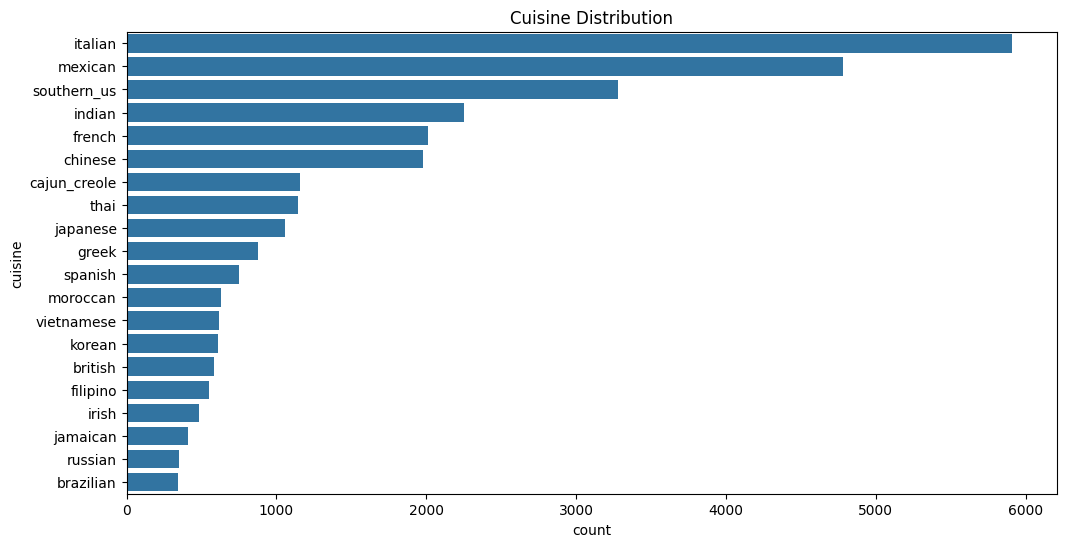

,proportion
cuisine,
italian,19.849533
mexican,16.067710
southern_us,11.012964
indian,7.553570
french,6.747498
chinese,6.650097
cajun_creole,3.892658
thai,3.848996
japanese,3.543360


In [53]:
plt.figure(figsize=(12,6))
sns.countplot(y=train['cuisine'], order=train['cuisine'].value_counts().index)
plt.title("Cuisine Distribution")
plt.show()

train['cuisine'].value_counts(normalize=True) * 100


Helps you see which cuisines dominate (e.g., Mexican, Italian, Indian)

Step 3: Ingredients Count per Recipe

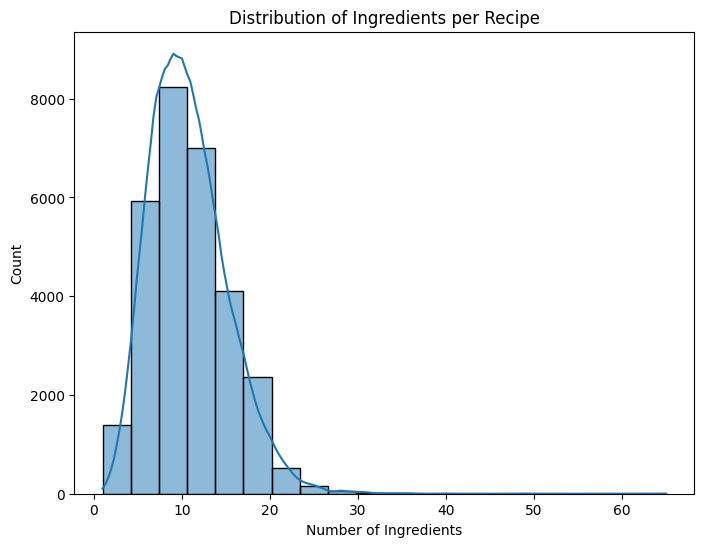

,num_ingredients
count,29774.000000
mean,10.770269
std,4.423917
min,1.000000
25%,8.000000
50%,10.000000
75%,13.000000
max,65.000000


In [54]:
train['num_ingredients'] = train['ingredients'].apply(len)

plt.figure(figsize=(8,6))
sns.histplot(train['num_ingredients'], kde=True, bins=20)
plt.title("Distribution of Ingredients per Recipe")
plt.xlabel("Number of Ingredients")
plt.show()

train['num_ingredients'].describe()


Insights:

Minimum, maximum ingredients

Are some cuisines more complex?

✔ Step 4: Top 20 Most Frequent Ingredients

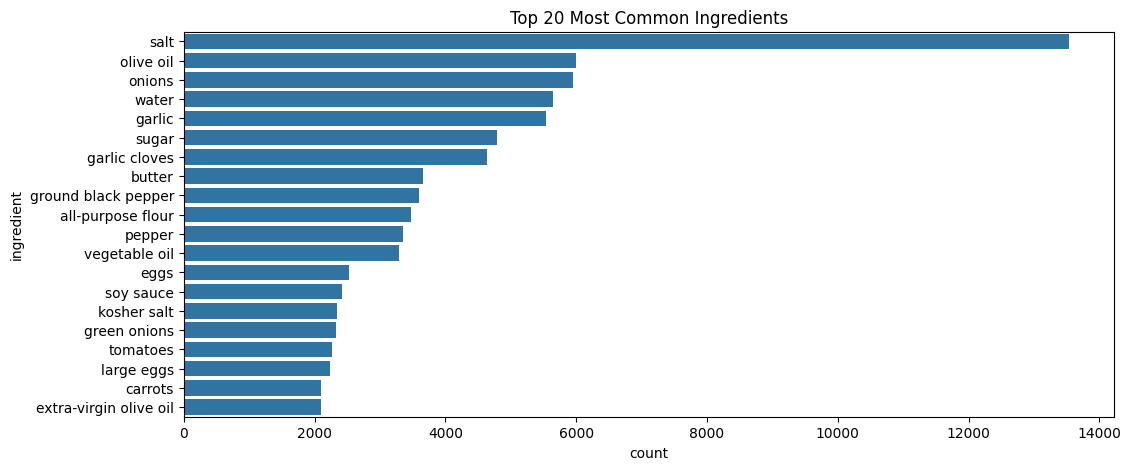

In [55]:
from collections import Counter

all_ingredients = [ing.lower().strip() for recipe in train['ingredients'] for ing in recipe]
ingredient_counts = Counter(all_ingredients).most_common(20)

# Convert to DataFrame for plotting
ing_df = pd.DataFrame(ingredient_counts, columns=['ingredient', 'count'])

plt.figure(figsize=(12,5))
sns.barplot(x='count', y='ingredient', data=ing_df)
plt.title("Top 20 Most Common Ingredients")
plt.show()


Step 5: Ingredients vs Cuisine (Key Insight)

In [56]:
train['has_soy_sauce'] = train['ingredients'].apply(lambda x: 'soy sauce' in [i.lower() for i in x])
train.groupby('cuisine')['has_soy_sauce'].mean().sort_values(ascending=False).head(10)


,has_soy_sauce
cuisine,
korean,0.502463
chinese,0.500505
japanese,0.394313
filipino,0.309222
thai,0.221640
vietnamese,0.187702
jamaican,0.125000
indian,0.008448
irish,0.008247


Example: Which cuisines use “soy sauce” the most?

Helps identify cuisine-specific features

✔ Step 6 (Optional but Amazing): WordCloud by Cuisine

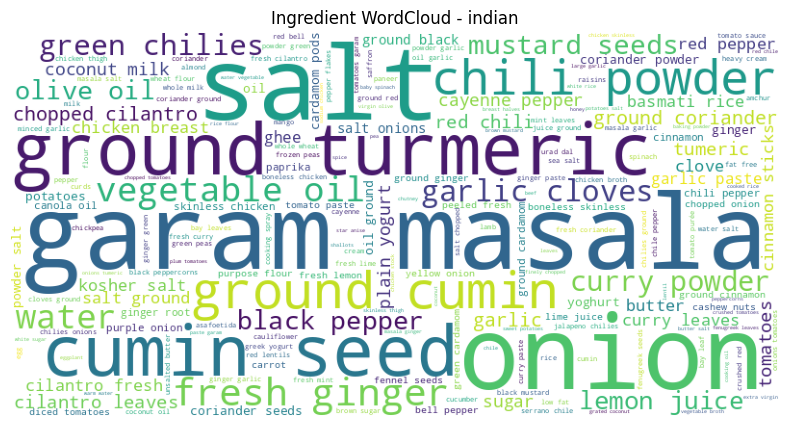

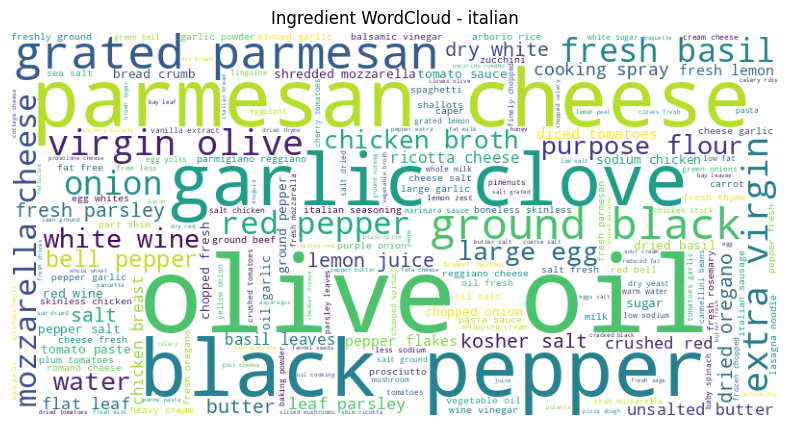

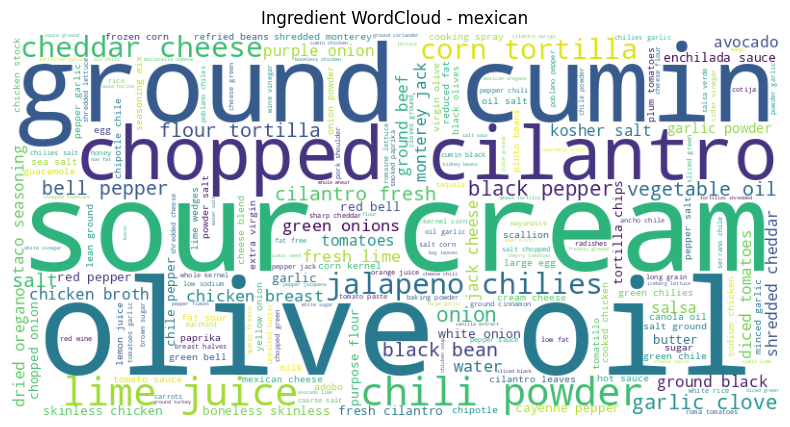

In [57]:
from wordcloud import WordCloud

def plot_wordcloud(cuisine):
    text = " ".join(
        ing.lower().strip()
        for recipe in train[train['cuisine'] == cuisine]['ingredients']
        for ing in recipe
    )
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wc)
    plt.axis("off")
    plt.title(f"Ingredient WordCloud - {cuisine}")
    plt.show()

plot_wordcloud("indian")
plot_wordcloud("italian")
plot_wordcloud("mexican")


#4: Split for Validation

In [8]:
# ---- 4. Train/validation split ----
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train split:", X_train.shape, "Val split:", X_val.shape)

Train split: (23819, 4479) Val split: (5955, 4479)


#5: Build a model to perform the cuisine prediction

Now we split, train, evaluate:

Example (Logistic Regression):

Validation Accuracy: 0.5703298179619802


<Axes: xlabel='step', ylabel='loss'>

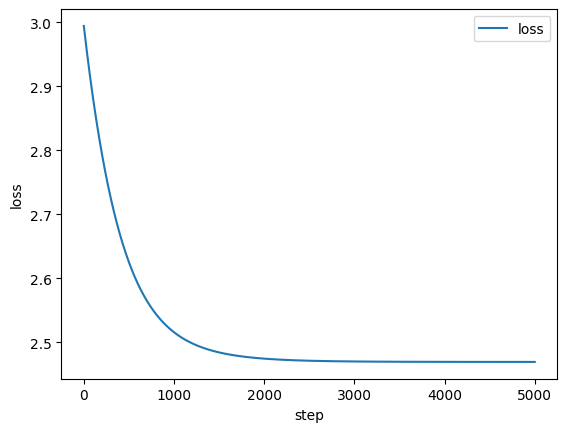

In [9]:
# ---- 5. Fit your custom Multiclass Logistic Regression ----
model = Multiclass()
model.fit(X, y)   # y are cuisine strings

# ---- 6. Evaluate on validation set ----
y_val_pred_idx = model.predict(X)              # indices 0..K-1
# Map indices back to label strings using the fitted OneHotEncoder
class_labels_full = onehot_encoder.categories_[0]       # array of cuisine labels
y_val_pred = class_labels_full[y_val_pred_idx]

val_acc = accuracy_score(y, y_val_pred)
print("Validation Accuracy:", val_acc)

# Optional: loss curve
model.loss_plot()

# # ---- 7. Retrain on full training data for final model ----
# model_full = Multiclass()
# model_full.fit(X, y)  # fit on all data

# After this fit, onehot_encoder is re-fitted on all labels
# class_labels_full = onehot_encoder.categories_[0]


<Figure size 1200x1000 with 0 Axes>

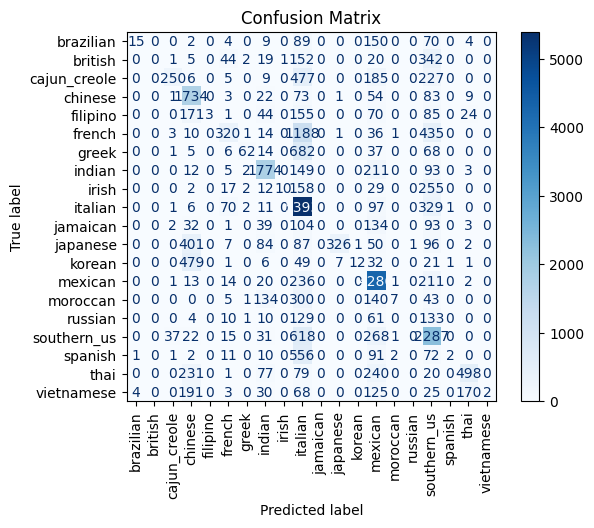

In [10]:
cm = confusion_matrix(y, y_val_pred, labels=class_labels_full)
plt.figure(figsize=(12,10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels_full)
disp.plot(cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix")
plt.show()


#6: Train on full data & predict test set

In [12]:
model_full = Multiclass()
model_full.fit(X, y)

class_labels_full = onehot_encoder.categories_[0]
test_pred_idx = model_full.predict(X_test_final)
test_pred = class_labels_full[test_pred_idx]

submission = pd.DataFrame({
    "Id": test["id"],
    "Category": test_pred
})
submission.to_csv("submission.csv", index=False)


- Earlier: you created features using word-level TF-IDF (ingredients_str and ngram_range=(1,1)), giving (29774, 2277).

- Now: in this code, you create features where each ingredient string is one feature (what you explicitly wanted).

Both are valid ways of “creating features from each data item”.
The code above also completes the second part: build a model to perform this task.